Set up the environment

# Session Title: Artificial Netural Networks for classification

**Instructor:** Zahra Sadeghi

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

np.random.seed(42)


 Create artificial moon data

In [ ]:
X, y = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("First 5 observations:")
print(X[:5])

print("First 5 labels:")
print(y[:5])


X shape: (1000, 2)
y shape: (1000,)
First 5 observations:
[[-0.14176498  0.55823629]
 [ 1.19796627 -0.30399544]
 [ 0.759391    0.1102501 ]
 [ 0.02331452 -0.60356298]
 [-0.80797972  0.54846574]]
First 5 labels:
[1 1 1 1 0]


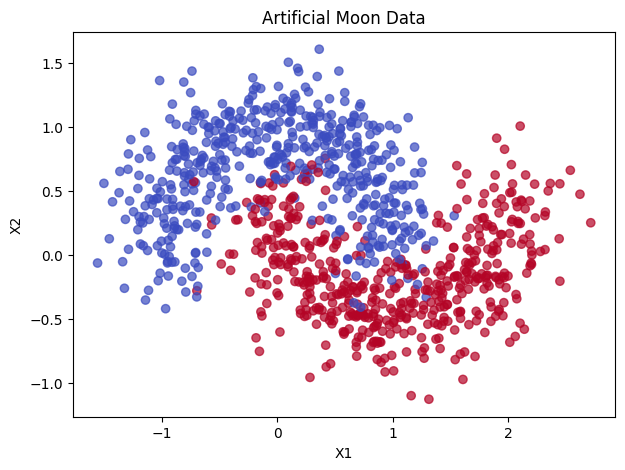

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Artificial Moon Data")
plt.show()


train_test_split(X, y, test_size=0.15, stratify=y)
Purpose: Preserves approximately the same proportion of each class in the training and test sets.

For example, if your target variable contains 80% No and 20% Yes, both datasets will have approximately the same proportions.

Use when: You are working on a classification problem, especially with imbalanced classes.



In [ ]:
#  split your dataset into two parts: a temporary dataset for training/validation and a test dataset for final evaluation.
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15, #Allocates 15% of the data to the test set and 85% to the temporary set.
    stratify=y,  #Preserves approximately the same class proportions in both sets as in the original dataset.
    random_state=42
)


groups = df['region']

stratify = groups #Preserves proportions of another categorical variable

This approach is useful when you want to maintain the distribution of another categorical variable, such as region or demographic category.

Now split the remaining 85% into training and validation.

Entire dataset (100%) : x_tem (85%), x_test (15%)
       
        

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,   # Allocates approximately 17.65% of the temporary dataset to validation.
    stratify=y_temp,   # Preserves approximately the same class proportions in the training and validation sets.
    random_state=42
)


In [ ]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (699, 2)
Validation: (151, 2)
Test: (150, 2)


The class proportions should be approximately the same because of stratify.

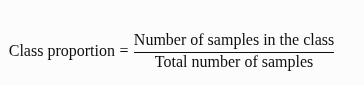

In [ ]:
print("Overall class proportions:")
print(np.bincount(y) / len(y)) #np.bincount() counts how many times each non-negative integer appears in an array.

print("\nTraining class proportions:")
print(np.bincount(y_train) / len(y_train))

print("\nValidation class proportions:")
print(np.bincount(y_val) / len(y_val))

print("\nTest class proportions:")
print(np.bincount(y_test) / len(y_test))


Overall class proportions:
[0.5 0.5]

Training class proportions:
[0.49928469 0.50071531]

Validation class proportions:
[0.50331126 0.49668874]

Test class proportions:
[0.5 0.5]


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)


In [ ]:
ann = MLPClassifier(
    hidden_layer_sizes=(10,), #  Hidden Layer (10 neurons)
    activation="relu",
    solver="sgd",
    max_iter=1000,
    random_state=42
)


ann.fit() — Training the model

During training, the ANN:

Takes the input features from X_train.
Makes predictions.
Compares its predictions with the actual labels in y_train.
Calculates the error (loss).
Adjusts its weights to reduce that error.
Repeats this process over multiple training iterations.

In [ ]:
ann.fit(X_train_scaled, y_train)


MLPClassifier(hidden_layer_sizes=(10,), max_iter=1000, random_state=42)

 ann.predict() — Making predictions

The purpose of predict() is to use the trained model to predict the target labels for the input data.

X_test: The input features for the test dataset.
y_pred: The labels predicted by the ANN.
Unlike fit(), predict() does not train the model or adjust its weights.


In [ ]:
y_train_pred = ann.predict(X_train_scaled)

train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

print("Training accuracy:", train_accuracy)


Training accuracy: 0.9427753934191703


In [ ]:
y_val_pred = ann.predict(X_val_scaled)

val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

print("Validation accuracy:", val_accuracy)


Validation accuracy: 0.9536423841059603


In [ ]:
cm = confusion_matrix(
    y_val,
    y_val_pred
)

print(cm)


[[74  2]
 [ 5 70]]


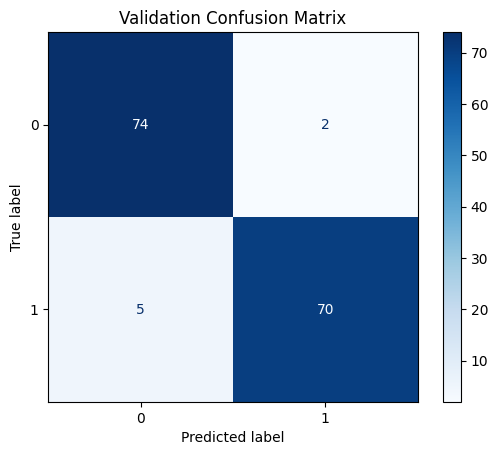

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    cmap="Blues"
)

plt.title("Validation Confusion Matrix")
plt.show()


Macro F1-score measures a classification model's performance across all classes, giving each class equal importance regardless of how many samples it contains.

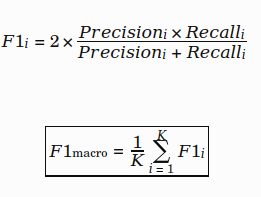

K = number of classes.
F1i = F1-score for class i.



Weighted F1 calculates the F1-score for each class and weights it according to the number of actual samples in that class.

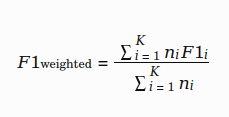

K = number of classes.
ni = number of actual samples in class i.
F1i = F1-score for class i.

In [ ]:
print(
    classification_report(
        y_val,
        y_val_pred
    )
)


              precision    recall  f1-score   support

           0       0.94      0.97      0.95        76
           1       0.97      0.93      0.95        75

    accuracy                           0.95       151
   macro avg       0.95      0.95      0.95       151
weighted avg       0.95      0.95      0.95       151



In [ ]:
y_val_prob = ann.predict_proba(X_val_scaled)[:, 1] #calculates the predicted probability that each observation in your validation set belongs to class 1.

print(y_val_prob[:10])


[0.12235205 0.98421529 0.99885412 0.22402001 0.22566547 0.00295783
 0.00906047 0.02456469 0.99228058 0.00370304]


In [ ]:
val_auc = roc_auc_score(
    y_val,
    y_val_prob
)

print("Validation ROC-AUC:", val_auc)


Validation ROC-AUC: 0.9919298245614036


cross-validation: Our validation set gives us one estimate of performance.

But that estimate can depend somewhat on how we happened to split the data.

5-fold stratified cross-validation:

Fold 1:  TRAIN TRAIN TRAIN VALID
Fold 2:  TRAIN TRAIN VALID TRAIN
Fold 3:  TRAIN VALID TRAIN TRAIN
Fold 4:  VALID TRAIN TRAIN TRAIN
Fold 5:  TRAIN TRAIN TRAIN VALID


In [ ]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ann", MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="relu", #hidden layer --- For scikit-learn's MLPClassifier, the output activation is selected automatically. binary: sigmoid, multiclass: softmax
        solver="adam",
        max_iter=1000,
        random_state=42
    ))
])


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [ ]:
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    return_train_score=True
)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
cv_results


{'fit_time': array([2.23079371, 0.66538811, 1.95368218, 0.6152823 , 0.8157599 ]),
 'score_time': array([0.0394063 , 0.01861548, 0.01862335, 0.01871729, 0.01862979]),
 'test_accuracy': array([0.94285714, 0.86428571, 0.96428571, 0.85714286, 0.81294964]),
 'train_accuracy': array([0.93381038, 0.86404293, 0.9391771 , 0.86404293, 0.87321429]),
 'test_precision': array([0.95588235, 0.88059701, 0.97101449, 0.83783784, 0.76829268]),
 'train_precision': array([0.93862816, 0.85172414, 0.93006993, 0.85664336, 0.85910653]),
 'test_recall': array([0.92857143, 0.84285714, 0.95714286, 0.88571429, 0.9       ]),
 'train_recall': array([0.92857143, 0.88214286, 0.95      , 0.875     , 0.89285714]),
 'test_f1': array([0.94202899, 0.86131387, 0.96402878, 0.86111111, 0.82894737]),
 'train_f1': array([0.93357271, 0.86666667, 0.93992933, 0.86572438, 0.87565674]),
 'test_roc_auc': array([0.98591837, 0.9444898 , 0.99244898, 0.92979592, 0.90848861]),
 'train_roc_auc': array([0.97901946, 0.94098822, 0.97844342, 0

In [ ]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:

    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric:10s}: "
        f"{scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )


accuracy  : 0.888 +/- 0.057
precision : 0.883 +/- 0.075
recall    : 0.903 +/- 0.039
f1        : 0.891 +/- 0.052
roc_auc   : 0.952 +/- 0.032
